# Post-layer-1 token-length spacing

This notebook tests whether the spacing between consecutive tokens is related to the length of the earlier token after the layer-1 MLP. It compares `blocks.1.hook_resid_mid` (pre-MLP), `blocks.1.hook_mlp_out` (the MLP increment), and `blocks.1.hook_resid_post` (post-layer-1). The main statistics are held-out GroupKFold R² values, with within-segment shuffled-length nulls.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_score

PROJECT_ROOT = next(
    p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent,
                Path.cwd().parent.parent.parent]
    if (p / "results/line_breaks_results").exists()
)
sys.path.insert(0, str(PROJECT_ROOT / "notebooks/06_layer1_mechanisms"))
from common import load_context, newline_positions
from project_main import data

N_EXAMPLES = 256
BATCH_SIZE = 32
SEED = 7011
SITE_NAMES = [
    "blocks.1.hook_resid_pre",
    "blocks.1.hook_resid_mid",
    "blocks.1.hook_mlp_out",
    "blocks.1.hook_resid_post",
]

ctx = load_context(SEED)
model, vocab, cfg, device = ctx.model, ctx.vocab, ctx.cfg, ctx.device
print("checkpoint", ctx.checkpoint["step"], "device", device)
print("sites", SITE_NAMES)

token_batches, cache_batches = [], {name: [] for name in SITE_NAMES}
for start in range(0, N_EXAMPLES, BATCH_SIZE):
    size = min(BATCH_SIZE, N_EXAMPLES - start)
    batch = data.make_batch(
        batch_size=size, vocab=vocab, task_cfg=cfg["task"],
        device=device, seed=SEED + start,
    )
    with torch.no_grad():
        _, cache = model.run_with_cache(
            batch.tokens, prepend_bos=False, names_filter=SITE_NAMES,
        )
    token_batches.append(batch.tokens.detach().cpu().numpy())
    for name in SITE_NAMES:
        cache_batches[name].append(cache[name].detach().cpu().numpy())

tokens_batch = np.concatenate(token_batches, axis=0)
activations = {
    name: np.concatenate(values, axis=0)
    for name, values in cache_batches.items()
}
print("examples", len(tokens_batch), "sequence length", tokens_batch.shape[1])
print("activation shape", activations[SITE_NAMES[0]].shape)

def token_length(token_id):
    name = vocab.decode_token(int(token_id))
    if name in {"BOS", "_NEWLINE_"}:
        return np.nan
    return float(data.extract_character_count(name))

def make_records(row, site_acts, example):
    """Return transitions inside each newline-delimited content segment."""
    records = []
    nls = newline_positions(row, vocab)
    boundaries = [-1] + nls + [len(row)]
    for segment, (left, right) in enumerate(zip(boundaries[:-1], boundaries[1:])):
        positions = [
            p for p in range(left + 1, right)
            if vocab.decode_token(int(row[p])) not in {"BOS", "_NEWLINE_"}
        ]
        if len(positions) < 4:
            continue
        positions = np.asarray(positions, dtype=int)
        lengths = np.asarray([token_length(row[p]) for p in positions])
        # Count before each token, measured in characters already consumed.
        counts = []
        running = 0.0
        for p in positions:
            counts.append(running)
            running += lengths[len(counts) - 1]
        records.append({
            "example": example,
            "segment": segment,
            "positions": positions,
            "lengths": lengths,
            "counts": np.asarray(counts),
            "position": np.arange(len(positions), dtype=float),
            **{name: site_acts[name][positions] for name in SITE_NAMES},
        })
    return records

records = [
    record
    for example in range(len(tokens_batch))
    for record in make_records(
        tokens_batch[example],
        {name: activations[name][example] for name in SITE_NAMES},
        example,
    )
]
print("usable segments", len(records))
print("segment length median", np.median([len(r["positions"]) for r in records]))


Building vocab...
('BOS', '_NEWLINE_')
checkpoint 10000 device cpu
sites ['blocks.1.hook_resid_pre', 'blocks.1.hook_resid_mid', 'blocks.1.hook_mlp_out', 'blocks.1.hook_resid_post']


examples 256 sequence length 150
activation shape (256, 150, 128)
usable segments 2241
segment length median 16.0


## Spacing models

For each newline-delimited segment, the earlier-token length predicts the transition from token `i` to token `i+1`. The signed displacement is measured along the segment's first PCA axis, oriented toward increasing cumulative character count; Euclidean displacement is also tested. The held-out models compare position and cumulative count alone against position, cumulative count, and earlier-token length.

In [2]:
def oriented_axis(points, lengths):
    """First PCA axis, oriented toward increasing cumulative character count."""
    pca = PCA(n_components=1, random_state=7012).fit(points)
    axis = pca.components_[0]
    coordinate = points @ axis
    cumulative = np.r_[0.0, np.cumsum(lengths[:-1])]
    if np.corrcoef(coordinate, cumulative)[0, 1] < 0:
        axis = -axis
    return axis

def site_transition_rows(site_name):
    rows = []
    for group, record in enumerate(records):
        points = record[site_name]
        axis = oriented_axis(points, record["lengths"])
        coordinate = points @ axis
        signed_delta = np.diff(coordinate)
        euclidean_delta = np.linalg.norm(np.diff(points, axis=0), axis=1)
        lengths = record["lengths"][:-1]
        counts = record["counts"][:-1]
        positions = record["position"][:-1]
        for i in range(len(signed_delta)):
            rows.append({
                "group": group,
                "signed_delta": signed_delta[i],
                "euclidean_delta": euclidean_delta[i],
                "earlier_length": lengths[i],
                "count_before": counts[i],
                "position": positions[i],
            })
    return pd.DataFrame(rows)

def summarize_site(site_name):
    df = site_transition_rows(site_name)
    x = df[["earlier_length"]].to_numpy()
    y_signed = df["signed_delta"].to_numpy()
    y_euclidean = df["euclidean_delta"].to_numpy()
    simple_signed = LinearRegression().fit(x, y_signed)
    simple_euclidean = LinearRegression().fit(x, y_euclidean)

    # Controls test whether length explains anything beyond position/count.
    controls = df[["position", "count_before"]].to_numpy()
    full = df[["position", "count_before", "earlier_length"]].to_numpy()
    groups = df["group"].to_numpy()
    splitter = GroupKFold(n_splits=5)
    def cv_r2(target, features):
        return float(np.mean(cross_val_score(
            LinearRegression(), features, target,
            groups=groups, cv=splitter, scoring="r2",
        )))
    signed_control_cv = cv_r2(y_signed, controls)
    signed_full_cv = cv_r2(y_signed, full)
    euclidean_control_cv = cv_r2(y_euclidean, controls)
    euclidean_full_cv = cv_r2(y_euclidean, full)

    # Within-segment shuffled lengths give a null that preserves all geometry
    # and all segment-level length distributions.
    rng = np.random.default_rng(7013)
    null_signed_r2, null_euclidean_r2 = [], []
    for _ in range(100):
        shuffled = df.copy()
        shuffled["earlier_length"] = (
            shuffled.groupby("group", group_keys=False)["earlier_length"]
            .transform(lambda values: values.sample(frac=1, random_state=int(rng.integers(1_000_000))).to_numpy())
        )
        null_signed_r2.append(LinearRegression().fit(
            shuffled[["earlier_length"]], y_signed).score(
                shuffled[["earlier_length"]], y_signed))
        null_euclidean_r2.append(LinearRegression().fit(
            shuffled[["earlier_length"]], y_euclidean).score(
                shuffled[["earlier_length"]], y_euclidean))
    return {
        "site": site_name,
        "n_transitions": len(df),
        "simple_signed_r2": simple_signed.score(x, y_signed),
        "simple_signed_corr": np.corrcoef(df["earlier_length"], y_signed)[0, 1],
        "simple_euclidean_r2": simple_euclidean.score(x, y_euclidean),
        "simple_euclidean_corr": np.corrcoef(df["earlier_length"], y_euclidean)[0, 1],
        "signed_control_cv_r2": signed_control_cv,
        "signed_full_cv_r2": signed_full_cv,
        "signed_incremental_cv_r2": signed_full_cv - signed_control_cv,
        "euclidean_control_cv_r2": euclidean_control_cv,
        "euclidean_full_cv_r2": euclidean_full_cv,
        "euclidean_incremental_cv_r2": euclidean_full_cv - euclidean_control_cv,
        "signed_null_r2_mean": np.mean(null_signed_r2),
        "signed_null_r2_p95": np.quantile(null_signed_r2, .95),
        "euclidean_null_r2_mean": np.mean(null_euclidean_r2),
        "euclidean_null_r2_p95": np.quantile(null_euclidean_r2, .95),
    }

summary = pd.DataFrame([summarize_site(name) for name in SITE_NAMES])
display(summary.round(4))


,site,n_transitions,simple_signed_r2,simple_signed_corr,simple_euclidean_r2,simple_euclidean_corr,signed_control_cv_r2,signed_full_cv_r2,signed_incremental_cv_r2,euclidean_control_cv_r2,euclidean_full_cv_r2,euclidean_incremental_cv_r2,signed_null_r2_mean,signed_null_r2_p95,euclidean_null_r2_mean,euclidean_null_r2_p95
0,blocks.1.hook_resid_pre,33765,0.1323,-0.3638,0.0147,-0.1212,-0.0000,0.1327,0.1327,0.0020,0.0173,0.0153,0.0001,0.0002,0.0002,0.0004
1,blocks.1.hook_resid_mid,33765,0.0112,-0.1060,0.0027,-0.0520,0.0158,0.0258,0.0099,-0.0000,0.0026,0.0026,0.0014,0.0019,0.0001,0.0003
2,blocks.1.hook_mlp_out,33765,0.0020,-0.0451,0.0009,0.0296,0.3238,0.3240,0.0001,0.2715,0.2745,0.0030,0.0004,0.0009,0.0008,0.0012
3,blocks.1.hook_resid_post,33765,0.0024,-0.0488,0.0003,0.0160,0.3031,0.3034,0.0003,0.2473,0.2489,0.0016,0.0009,0.0014,0.0006,0.0010


## MLP-specific test

If the MLP introduces a length-dependent spacing component, the difference between consecutive `hook_mlp_out` vectors should itself be predictable from earlier-token length after controlling for position and cumulative count.

In [3]:
# Does the MLP increment itself carry the length-dependent displacement?
mlp_rows = []
for group, record in enumerate(records):
    post_points = record["blocks.1.hook_resid_post"]
    axis = oriented_axis(post_points, record["lengths"])
    mlp_delta = np.diff(record["blocks.1.hook_mlp_out"], axis=0) @ axis
    post_delta = np.diff(post_points, axis=0) @ axis
    lengths = record["lengths"][:-1]
    counts = record["counts"][:-1]
    positions = record["position"][:-1]
    for i in range(len(mlp_delta)):
        mlp_rows.append({
            "group": group, "mlp_delta": mlp_delta[i],
            "post_delta": post_delta[i], "earlier_length": lengths[i],
            "count_before": counts[i], "position": positions[i],
        })
mlp_df = pd.DataFrame(mlp_rows)
groups = mlp_df["group"].to_numpy()
splitter = GroupKFold(n_splits=5)
controls = mlp_df[["position", "count_before"]]
full = mlp_df[["position", "count_before", "earlier_length"]]
mlp_control = np.mean(cross_val_score(LinearRegression(), controls, mlp_df["mlp_delta"], groups=groups, cv=splitter, scoring="r2"))
mlp_full = np.mean(cross_val_score(LinearRegression(), full, mlp_df["mlp_delta"], groups=groups, cv=splitter, scoring="r2"))
post_control = np.mean(cross_val_score(LinearRegression(), controls, mlp_df["post_delta"], groups=groups, cv=splitter, scoring="r2"))
post_full = np.mean(cross_val_score(LinearRegression(), full, mlp_df["post_delta"], groups=groups, cv=splitter, scoring="r2"))
print("MLP-output displacement CV R2: controls", round(float(mlp_control), 4), "full", round(float(mlp_full), 4), "increment", round(float(mlp_full - mlp_control), 4))
print("Post-layer-1 signed displacement CV R2 on same axis: controls", round(float(post_control), 4), "full", round(float(post_full), 4), "increment", round(float(post_full - post_control), 4))
print("MLP displacement/length correlation", round(float(np.corrcoef(mlp_df["mlp_delta"], mlp_df["earlier_length"])[0, 1]), 4))


MLP-output displacement CV R2: controls 0.3465 full 0.3466 increment 0.0001
Post-layer-1 signed displacement CV R2 on same axis: controls 0.3031 full 0.3034 increment 0.0003
MLP displacement/length correlation -0.0125


## Scatter plots

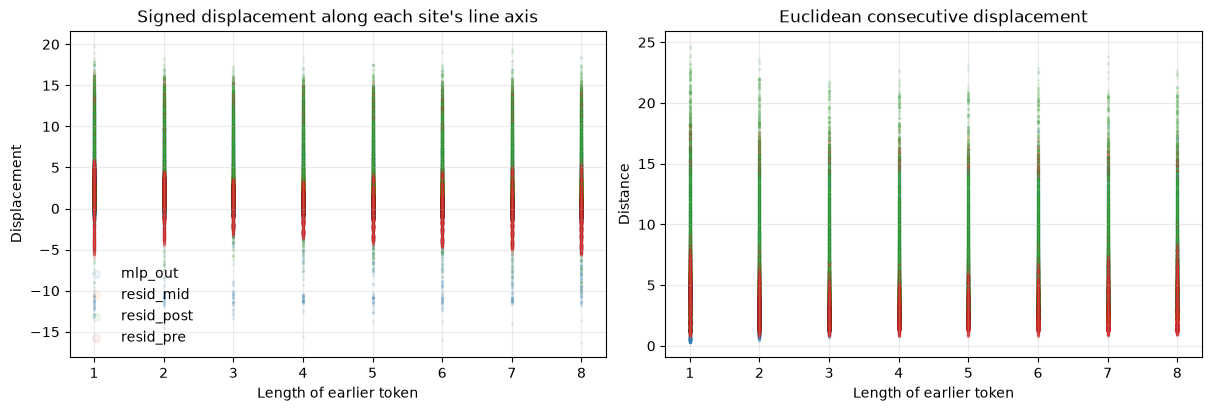

In [4]:
# Compact visual summary of the measured effect sizes.
plot_rows = []
for site in SITE_NAMES:
    df = site_transition_rows(site)
    df["site"] = site.replace("blocks.1.hook_", "")
    plot_rows.append(df)
plot_df = pd.concat(plot_rows, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for label, group in plot_df.groupby("site"):
    axes[0].scatter(group["earlier_length"], group["signed_delta"], s=2, alpha=.08, label=label)
    axes[1].scatter(group["earlier_length"], group["euclidean_delta"], s=2, alpha=.08, label=label)
axes[0].set_title("Signed displacement along each site's line axis")
axes[1].set_title("Euclidean consecutive displacement")
for ax in axes:
    ax.set_xlabel("Length of earlier token")
    ax.grid(alpha=.25)
axes[0].set_ylabel("Displacement")
axes[1].set_ylabel("Distance")
axes[0].legend(frameon=False, markerscale=4)
plt.show()
